In [2]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
from skimage import exposure

In [3]:
def plot_spatial_with_border(adata, ct, img_key="hires", 
                              cmap="magma", spot_size=8,
                              border_color="lime", border_width=0.8,
                              min_percentile=50, figsize=(8, 8)):
    """
    Plot spatial cell type scores with a neon border around each spot.
    """
    library_id = list(adata.uns["spatial"].keys())[0]
    img = adata.uns["spatial"][library_id]["images"][img_key]
    scale = adata.uns["spatial"][library_id]["scalefactors"][f"tissue_{img_key}_scalef"]
    
    coords = adata.obsm["spatial"] * scale  # pixel coordinates
    scores = adata.obs[ct].values

    # Only show spots above threshold
    threshold = np.percentile(scores, min_percentile)
    mask = scores > threshold

    # Normalize scores for colormap
    vmin, vmax = scores[mask].min(), np.percentile(scores[mask], 99)
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    colors = plt.get_cmap(cmap)(norm(scores[mask]))

    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(img)

    # ── Draw border layer first (slightly larger, neon color) ─────────────────
    ax.scatter(
        coords[mask, 0], coords[mask, 1],
        s=spot_size * 1.6,        # slightly bigger than fill
        c=border_color,
        linewidths=0,
        zorder=2,
    )

    # ── Draw filled spots on top ───────────────────────────────────────────────
    sc_fill = ax.scatter(
        coords[mask, 0], coords[mask, 1],
        s=spot_size,
        c=colors,
        linewidths=0,
        zorder=3,
    )

    # Colorbar
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    plt.colorbar(sm, ax=ax, shrink=0.4, label=ct)

    ax.set_title(ct, fontsize=12)
    ax.axis("off")
    plt.tight_layout()
    return fig

In [4]:
def plot_spatial_with_border_v2(adata, ct, ax, fig, img_key="hires", 
                              cmap="magma", spot_size=8,
                              border_color="lime", border_width=0.8,
                              min_percentile=50):
    """
    Plot spatial cell type scores with a neon border around each spot.
    """
    library_id = list(adata.uns["spatial"].keys())[0]
    img = adata.uns["spatial"][library_id]["images"][img_key]
    scale = adata.uns["spatial"][library_id]["scalefactors"][f"tissue_{img_key}_scalef"]
    
    coords = adata.obsm["spatial"] * scale  # pixel coordinates
    scores = adata.obs[ct].values

    #safe guard empy scores
    if np.all(scores == 0) or np.all(np.isnan(scores)):
        ax.imshow(img)
        ax.set_title(f"{ct}\n(no expression)", fontsize=8)
        ax.axis("off")
        return

    
    # Only show spots above threshold
    threshold = np.percentile(scores, min_percentile)
    mask = scores > threshold

    # Normalize scores for colormap
    vmin, vmax = scores[mask].min(), np.percentile(scores[mask], 99)
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    colors = plt.get_cmap(cmap)(norm(scores[mask]))

    #fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(img)

    # ── Draw border layer first (slightly larger, neon color) ─────────────────
    ax.scatter(
        coords[mask, 0], coords[mask, 1],
        s=spot_size * 1.6,        # slightly bigger than fill
        c=border_color,
        linewidths=0,
        zorder=2,
    )

    # ── Draw filled spots on top ───────────────────────────────────────────────
    sc_fill = ax.scatter(
        coords[mask, 0], coords[mask, 1],
        s=spot_size,
        c=colors,
        linewidths=0,
        zorder=3,
    )

    # Colorbar
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    plt.colorbar(sm, ax=ax, shrink=0.4, label=ct)

    ax.set_title(ct, fontsize=12)
    ax.axis("off")
    plt.tight_layout()
    return fig

In [5]:
def marker_unique_excel(exl_file,sheet_name,cluster = "supertype.markers.combo",class_label = "class_label"):

    markers_df = pd.read_excel(exl_file,sheet_name=sheet_name)

    #interested in supertype.markers.combo and class_label and class_id_label
    markers_df = markers_df[[cluster,class_label]]
    markers_df = markers_df.dropna(subset=[cluster])
    #markers_df.to_csv("test.csv", index=False)

    markers_df['gene_list'] = markers_df[cluster].str.split(',').apply(
        lambda x: [g.strip() for g in x]
    )

    genes_long = (
        markers_df[[cluster, class_label]]
        .assign(gene=markers_df[cluster].str.split(','))
        .explode('gene')
    )

    genes_long['gene'] = genes_long['gene'].str.strip()
    genes_long = genes_long[genes_long['gene'] != '']  # remove empty strings

    gene_class_count = (
        genes_long.groupby('gene')[class_label]
        .nunique()
        .rename('n_classes')
    )

    unique_genes = gene_class_count[gene_class_count == 1].index

    unique_table = (
        genes_long[genes_long['gene'].isin(unique_genes)]
        [[class_label, 'gene']]
        .drop_duplicates()
        .sort_values([class_label, 'gene'])
        .reset_index(drop=True)
    )


    unique_marker_dict = (
        unique_table.groupby(class_label)['gene']
        .apply(list)
        .to_dict()
    )
        
    return unique_table, unique_marker_dict

In [6]:
def score_geneset(adata, genes, name):
    """Mean log-normalised expression of detected genes in the set."""
    present = [g for g in genes if g in adata.var_names]
    if len(present) == 0:
        adata.obs[name] = 0.0
        return 0
    expr = adata[:, present].X
    if hasattr(expr, "toarray"):
        expr = expr.toarray()
    adata.obs[name] = expr.mean(axis=1)
    return len(present)

In [7]:
def moran_filter_prep_v1(adata,markers,min_score=0.06,min_spots=50,k_neighbors=6):

    """
        version 1 of filtering spots prior to running moran correlation between celltypes 

        Return:
            masked_scores: dictionary containing filtered spot scores

    """
    score_cols = list(markers.keys())  # your cell type score columns

    passing = {}
    for ct in score_cols:
        if ct not in adata.obs.columns:
            continue
        scores = adata.obs[ct].values
        mask   = scores >= min_score
        n      = mask.sum()
        if n >= min_spots:
            passing[ct] = mask
            print(f"  {ct:30s}  passing spots: {n:4d} / {len(scores)}")
        else:
            print(f"  {ct:30s}  SKIPPED — only {n} spots above threshold")

    valid_cts = list(passing.keys())
    print(f"\n{len(valid_cts)} cell classes pass threshold")

    # ── Step 2: Build spatial weights on FULL spot set ───────────────────────────
    # Use all spots for the weight matrix — scores outside threshold become 0
    coords = adata.obsm['spatial']
    w = libpysal.weights.KNN.from_array(coords, k=k_neighbors)
    w.transform = 'R'   # row-standardize

    # ── Step 3: Prepare masked score vectors ─────────────────────────────────────
    # Zero out spots below threshold so only confirmed positive spots contribute
    masked_scores = {}
    for ct in valid_cts:
        scores          = adata.obs[ct].values.copy()
        scores[~passing[ct]] = 0.0
        # Standardize to zero mean, unit variance for comparability
        std = scores.std()
        if std > 0:
            scores = (scores - scores[scores > 0].mean()) / std
        masked_scores[ct] = scores

    return masked_scores,passing,w


In [8]:
def plot_celltype_overlay(adata, celltypes, img_key="hires", 
                          spot_size=1.4, alpha=0.7, min_threshold=0.3,
                          figsize=(10, 10),border_color="white",colors = cm.tab20.colors):
    """
    Overlay multiple cell types on the same spatial image.
    Each cell type gets a distinct color; spots are only shown
    if their score exceeds min_threshold (as a percentile).
    """
    library_id = list(adata.uns["spatial"].keys())[0]
    img = adata.uns["spatial"][library_id]["images"][img_key]
    scale = adata.uns["spatial"][library_id]["scalefactors"][f"tissue_{img_key}_scalef"]
    
    # Get spot coordinates (in image pixel space)
    coords = adata.obsm["spatial"] * scale  # shape: (n_spots, 2)
    
    # Assign a color per cell type
    #colors = cm.tab20.colors  # 20 distinct colors
    
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(img)
    ax.axis("off")
    
    legend_handles = []
    
    for i, ct in enumerate(celltypes):
        if ct not in adata.obs.columns:
            print(f"Warning: {ct} not found in adata.obs, skipping")
            continue
        
        scores = adata.obs[ct].values
        
        # Only plot spots above threshold percentile
        threshold = np.percentile(scores, min_threshold * 100)
        mask = scores > threshold
        
        # Normalize scores for alpha/size scaling
        s_norm = (scores[mask] - scores[mask].min()) / (scores[mask].max() - scores[mask].min() + 1e-8)
        
        color = colors[i % len(colors)]
        
        #scatter = ax.scatter(
        #    coords[mask, 0],
        #    coords[mask, 1],
        #    c=[color],
        #    s=spot_size * (1 + s_norm * 3),   # size scales with expression
        #    alpha=alpha * s_norm + 0.1,         # transparency scales with expression
        #    label=ct,
        #    linewidths=0,
        #)
        #legend_handles.append(scatter)

        # ── Draw border layer first (slightly larger, neon color) ─────────────────
        scatter = ax.scatter(
            coords[mask, 0],
            coords[mask, 1],
            s=spot_size * (1 + s_norm * 3), #spot_size * 1.6, #spot_size * (1 + s_norm * 3),        # slightly bigger than fill
            c=border_color,
            linewidths=1,
            alpha=alpha,
            zorder=2,
        )

        legend_handles.append(scatter)
        
        # ── Draw filled spots on top ───────────────────────────────────────────────
        sc_fill = ax.scatter(
            coords[mask, 0], 
            coords[mask, 1],
            s=spot_size * (1 + s_norm * 3),
            c=[color],
            linewidths=0,
            alpha=alpha,
            zorder=3,
            label=ct, 
        )
        legend_handles.append(sc_fill)
    
    ax.legend(
        loc="upper right",
        bbox_to_anchor=(1.3, 1),
        fontsize=7,
        markerscale=2,
        framealpha=0.8,
    )
    plt.title("Cell type overlay", fontsize=12)
    plt.tight_layout()
    return fig

# Load integrated spatial data 

Analysis from integrated and normalized data from spatial_pipeline.py

In [65]:
adata = sc.read_h5ad("Tuyu_Apr2026/spatial_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_016um.h5ad")
#adata = sc.read_h5ad("Tuyu_Apr2026/spatial_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_008um.h5ad")

In [66]:
adata

AnnData object with n_obs × n_vars = 83352 × 15546
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_counts', 'Astro-Epen', 'CB GABA', 'CB Glut', 'CNU-HYa GABA', 'CNU-HYa Glut', 'CNU-LGE GABA', 'CNU-MGE GABA', 'CTX-CGE GABA', 'CTX-MGE GABA', 'DG-IMN Glut', 'HY GABA', 'HY Glut', 'HY Gnrh1 Glut', 'HY MM Glut', 'IT-ET Glut', 'Immune', 'LSX GABA', 'MB Dopa', 'MB GABA', 'MB Glut', 'MB-HB Sero', 'MH-LH Glut', 'MY GABA', 'MY Glut', 'NP-CT-L6b Glut', 'OB-CR Glut', 'OB-IMN GABA', 'OPC-Oligo', 'P GABA', 'P Glut', 'Pineal Glut', 'TH Glut', 'Vascular', 'leiden', 'gfp_candidates', 'gfp_probe'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'mean

In [67]:
marker_table_allen,marker_allen = marker_unique_excel('/research/groups/mackgrp/home/demerson/AIB/yao_et_al_Nature_2023.xlsx','supertype_annotation')
marker_allen['gfp_probe'] = ['Gfp', 'GFP', 'EGFP', 'eGFP', 'gfp', 'egfp','EGFP-L10a', 'Gfp-L10a', 'td-Tomato', 'mCherry']

In [68]:
for ct, genes in marker_allen.items():
    n = score_geneset(adata, genes, ct)
    print(f"  {ct}: {n}/{len(genes)}")
    

celltype_scores = list(marker_allen.keys())

  Astro-Epen: 31/34
  CB GABA: 8/9
  CB Glut: 1/1
  CNU-HYa GABA: 39/41
  CNU-HYa Glut: 21/24
  CNU-LGE GABA: 29/30
  CNU-MGE GABA: 11/12
  CTX-CGE GABA: 16/18
  CTX-MGE GABA: 22/26
  DG-IMN Glut: 7/7
  HY GABA: 29/38
  HY Glut: 32/40
  HY Gnrh1 Glut: 1/1
  HY MM Glut: 1/1
  IT-ET Glut: 101/115
  Immune: 12/12
  LSX GABA: 27/29
  MB Dopa: 4/4
  MB GABA: 25/30
  MB Glut: 50/56
  MB-HB Sero: 0/3
  MH-LH Glut: 9/10
  MY GABA: 17/24
  MY Glut: 25/33
  NP-CT-L6b Glut: 21/25
  OB-CR Glut: 2/4
  OB-IMN GABA: 25/30
  OPC-Oligo: 10/11
  P GABA: 20/24
  P Glut: 18/20
  Pineal Glut: 1/1
  TH Glut: 30/30
  Vascular: 8/9
  gfp_probe: 1/10


In [69]:
class_genes = marker_table_allen.groupby('class_label')['gene'].unique().reset_index()
class_genes.columns = ['class_label', 'genes']

panel_genes = set(adata.var_names.unique())

In [70]:
class_genes['genes_in_visium_16uM'] = class_genes['genes'].apply(
    lambda x: [g for g in x if g in panel_genes]
)

class_genes['n_genes_in_visium_16uM'] = class_genes['genes_in_visium_16uM'].apply(len)
class_genes['n_genes_total']    = class_genes['genes'].apply(len)
class_genes['pct_covered']      = (
    class_genes['n_genes_in_visium_16uM'] / class_genes['n_genes_total'] * 100
).round(1)

#class_genes['genes_present'] = class_genes['genes'].apply(
#    lambda x: [g for g in x if g in panel_genes]
#)

class_genes['genes_missing'] = class_genes['genes'].apply(
    lambda x: [g for g in x if g not in panel_genes]
)

class_genes = class_genes.rename(columns={'genes': 'allen_total_genes'})
class_genes = class_genes.rename(columns={'genes_missing': 'genes_not_in_panel'})

In [71]:
#class_genes.to_excel("allen_class_Gene_List_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_008um.xlsx", index=False)

### Inspecting all GFP probed spots and analyzing which class has the highest score excluding GFP_probe

In [72]:
#min_threshold = 0.999
gfp_scores = adata.obs['gfp_probe'].values
#threshold = np.percentile(scores, min_threshold * 100)
#threshold = gfp_scores[gfp_scores > 0]
gfp_adata = adata[gfp_scores > 0]

scores_df = gfp_adata.obs[marker_allen.keys()]
scores_df = scores_df.drop(columns=["gfp_probe"])
scores_df["predicted_celltype"] = scores_df.idxmax(axis=1)
counts = scores_df["predicted_celltype"].value_counts()


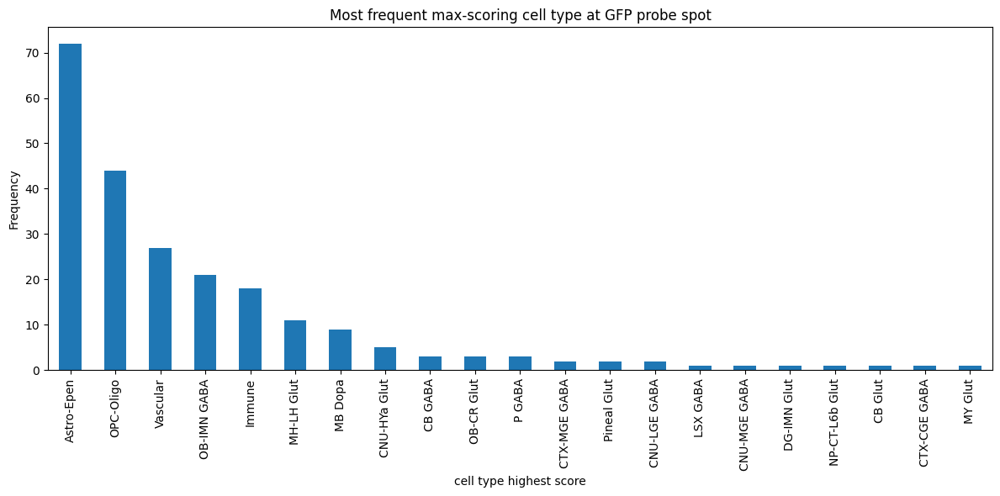

In [73]:
ax = counts.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_xlabel("cell type highest score")
ax.set_ylabel("Frequency")
ax.set_title("Most frequent max-scoring cell type at GFP probe spot")
#plt.savefig("spatial_gfp_spots_top_score_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_8uM_bar.png",dpi=300,bbox_inches="tight")
plt.savefig("spatial_gfp_spots_top_score_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_16uM_bar.png",dpi=300,bbox_inches="tight")
plt.tight_layout()
plt.show()

# Spatial feature plots — one panel per cell type 

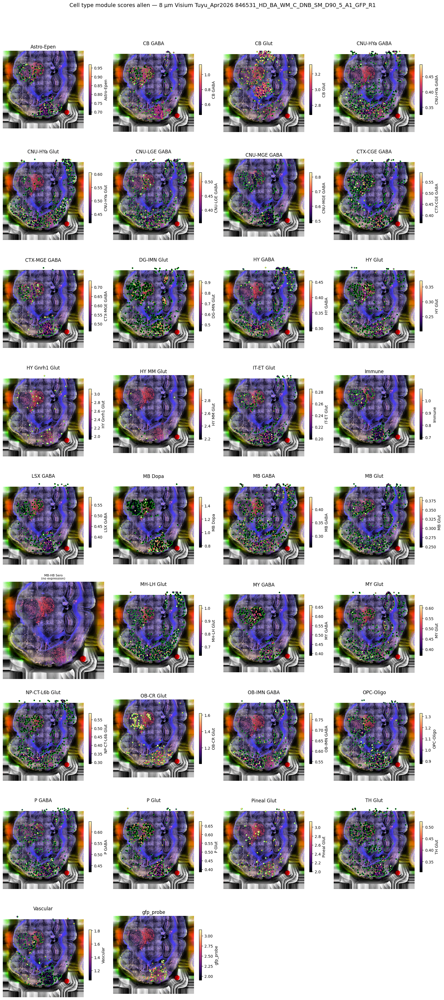

In [28]:
ncols = 4
nrows = -(-len(celltype_scores) // ncols)   # ceiling division

fig, axes = plt.subplots(nrows, ncols,figsize=(ncols * 4, nrows * 4))
axes = axes.flatten()
plot_type = 2

for i, ct in enumerate(celltype_scores):
    if plot_type == 1:
        sc.pl.spatial(
            adata,
            color=ct,
            ax=axes[i],
            show=False,
            title=ct,
            cmap="magma",
            size=1.4,
            vmin=0,
            vmax=np.percentile(adata.obs[ct], 99),  # clip top 1% for viz
            colorbar_loc=None,
        )
    else:
        fig = plot_spatial_with_border_v2(
            adata, ct,axes[i],fig,
            border_color="lime",      # neon green
            spot_size=10,
            min_percentile=99)
    
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Cell type module scores allen — 8 µm Visium Tuyu_Apr2026 846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1", fontsize=14, y=1.01)
plt.tight_layout()

#plt.savefig("spatial_celltype_scores_Tuyu_Apr2026 846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_8uM_v2.png", dpi=150, bbox_inches="tight")
#plt.savefig("spatial_celltype_scores_Tuyu_Apr2026 846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_8uM.png", dpi=150, bbox_inches="tight")
plt.show()

## Enhance Brightness / Contrast of the Tissue Image

In [29]:
adata

AnnData object with n_obs × n_vars = 78284 × 15028
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_counts', 'Astro-Epen', 'CB GABA', 'CB Glut', 'CNU-HYa GABA', 'CNU-HYa Glut', 'CNU-LGE GABA', 'CNU-MGE GABA', 'CTX-CGE GABA', 'CTX-MGE GABA', 'DG-IMN Glut', 'HY GABA', 'HY Glut', 'HY Gnrh1 Glut', 'HY MM Glut', 'IT-ET Glut', 'Immune', 'LSX GABA', 'MB Dopa', 'MB GABA', 'MB Glut', 'MB-HB Sero', 'MH-LH Glut', 'MY GABA', 'MY Glut', 'NP-CT-L6b Glut', 'OB-CR Glut', 'OB-IMN GABA', 'OPC-Oligo', 'P GABA', 'P Glut', 'Pineal Glut', 'TH Glut', 'Vascular', 'gfp_probe', 'leiden'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions',

In [30]:
img_key = "hires"  # or "lowres"
library_id = list(adata.uns["spatial"].keys())[0]

# Get the image
img = adata.uns["spatial"][library_id]["images"][img_key].copy()


Percentile-based contrast stretching  
- stretches or shrinks pixel values
- maps input intensity range to output range
- image has a narrow range of values, it can spread them out so the image looks less dim.


/lsf_tmp/290322525.tmpdir/ipykernel_2935185/1063799434.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, color=ct, cmap="magma", img_key=img_key)


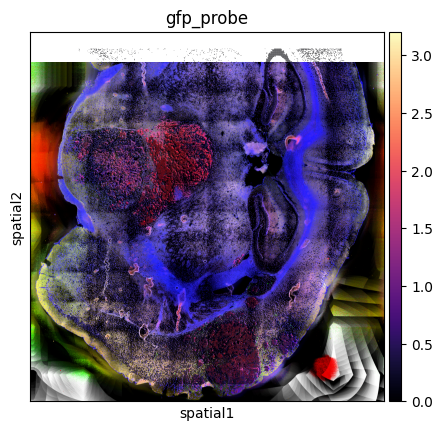

In [31]:
p2, p98 = np.percentile(img, (20, 98))
img_bright = exposure.rescale_intensity(img, in_range=(p2, p98))

adata.uns["spatial"][library_id]["images"][img_key] = img_bright
ct = "gfp_probe"
sc.pl.spatial(adata, color=ct, cmap="magma", img_key=img_key)

Option B: gamma correction, which remaps pixel intensities with a power law
gamma > 1 makes the image darker, especially in mid-tones.
gamma < 1 makes the image brighter.
gamma = 1 leaves the image essentially unchanged.

/lsf_tmp/290322525.tmpdir/ipykernel_2935185/3730178678.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, color=ct, cmap="magma", img_key=img_key)


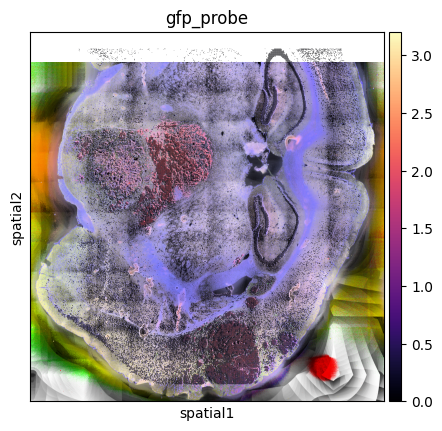

In [32]:
img_bright = exposure.adjust_gamma(img, gamma=0.5) #0.5
adata.uns["spatial"][library_id]["images"][img_key] = img_bright
ct = "gfp_probe"
sc.pl.spatial(adata, color=ct, cmap="magma", img_key=img_key)

CLAHE — adaptive local contrast enhancement  
- improves local contrast by processing the image in small tiles instead of using one global histogram
- enhances faint structures in darker or unevenly illuminated regions
- limits contrast amplification to avoid overboosting noise
- returns an equalized image, usually as floating-point data

/lsf_tmp/290322525.tmpdir/ipykernel_2935185/2808648906.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, color=ct, cmap="magma", img_key=img_key)


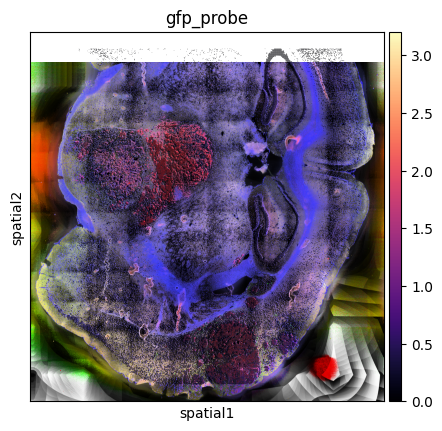

In [33]:
img_bright = exposure.equalize_adapthist(img, clip_limit=0.02) #0.03
adata.uns["spatial"][library_id]["images"][img_key] = img_bright
ct = "gfp_probe"
sc.pl.spatial(adata, color=ct, cmap="magma", img_key=img_key)

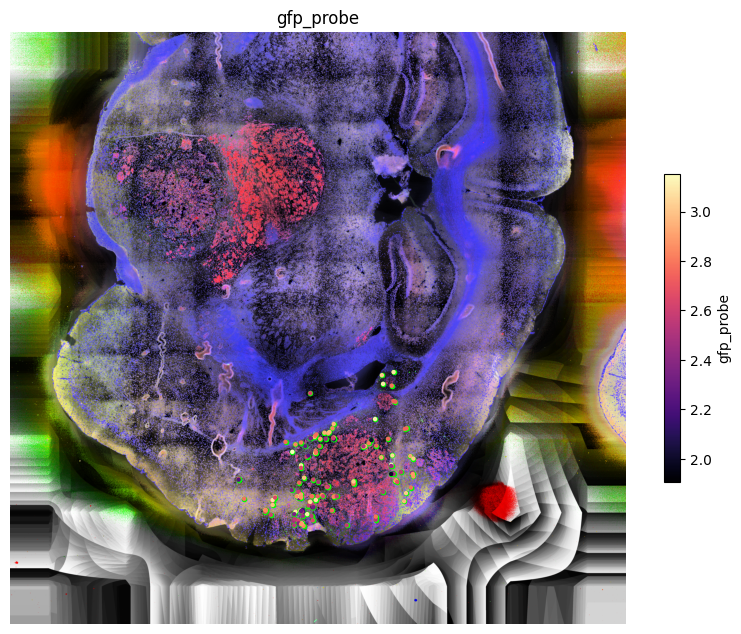

In [34]:
ct = "gfp_probe"
fig = plot_spatial_with_border(
    adata, ct=ct,
    border_color="lime",      # neon green
    spot_size=10,
    min_percentile=50,
)

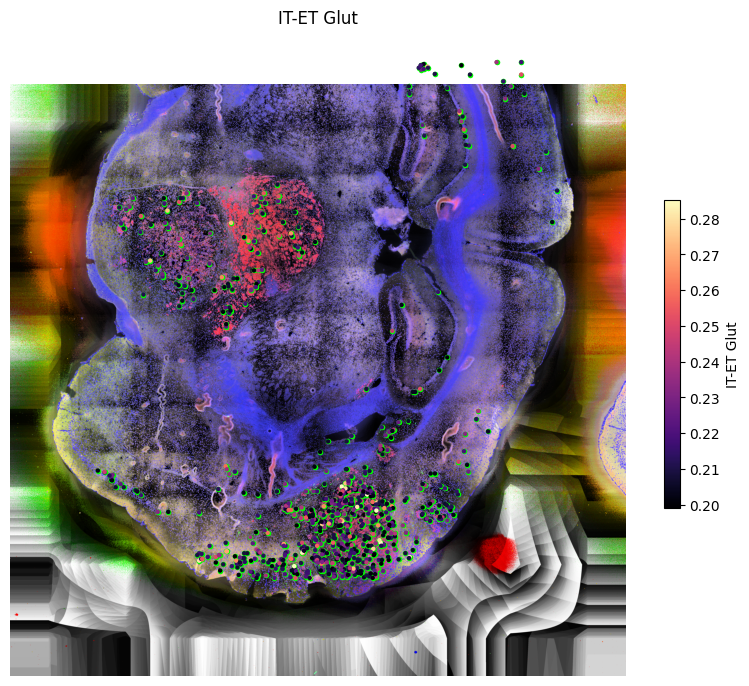

In [35]:
ct = "IT-ET Glut"
fig = plot_spatial_with_border(
    adata, ct=ct,
    border_color="lime",      # neon green
    spot_size=10,
    min_percentile=99,
)

## overlay cellytypes

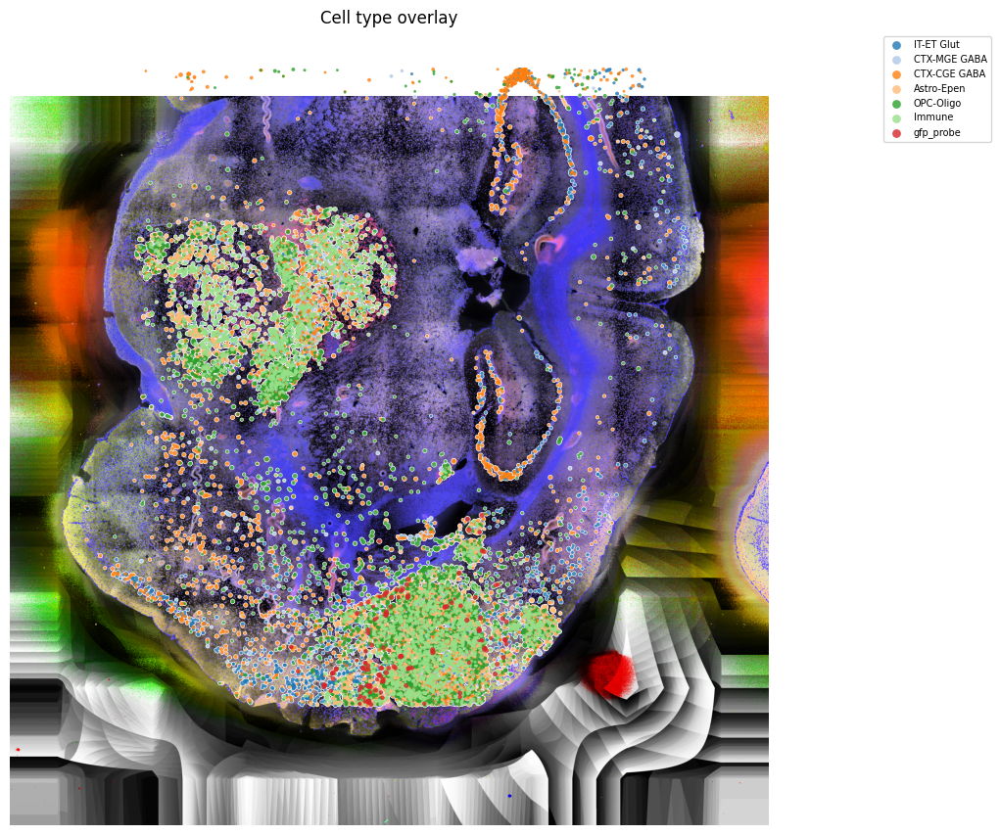

In [36]:
# Pick cell types you want to overlay (keep to ~5-8 for readability)
celltypes_to_overlay = [
    "IT-ET Glut", "CTX-MGE GABA", "CTX-CGE GABA",
    "Astro-Epen", "OPC-Oligo", "Immune","gfp_probe"
]

fig = plot_celltype_overlay(
    adata,
    celltypes=celltypes_to_overlay,
    img_key="hires",
    spot_size=4,          # increase if spots are hard to see originally 8
    alpha=0.8,            # originally 0.8
    min_threshold=0.95,    # only show top 50% expressing spots per cell type
)
#fig.savefig("celltype_overlay_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_8uM.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

## Side-by-side: Individual + Overlay Together

/lsf_tmp/290322525.tmpdir/ipykernel_2935185/3990046757.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, color=ct, ax=axes[i], show=False,
/lsf_tmp/290322525.tmpdir/ipykernel_2935185/3990046757.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, color=ct, ax=axes[i], show=False,
/lsf_tmp/290322525.tmpdir/ipykernel_2935185/3990046757.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, color=ct, ax=axes[i], show=False,
/lsf_tmp/290322525.tmpdir/ipykernel_2935185/3990046757.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, color=ct, ax=axes[i], show=False,
/lsf_tmp/290322525.tmpdir/ipykernel_2935185/3990046757.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, color=ct, ax=axes[i], show=False,
/lsf_tmp/290322525.tmpdir/ipykernel_2935185/3990046757.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl

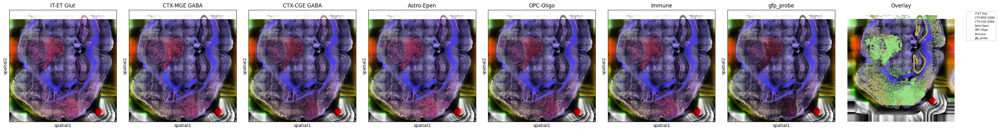

In [37]:
fig, axes = plt.subplots(1, len(celltypes_to_overlay) + 1,
                          figsize=((len(celltypes_to_overlay) + 1) * 4, 4))

# Individual plots
for i, ct in enumerate(celltypes_to_overlay):
    sc.pl.spatial(adata, color=ct, ax=axes[i], show=False,
                  title=ct, cmap="magma", colorbar_loc=None,
                  vmax=np.percentile(adata.obs[ct], 99))

# Overlay in last panel — draw manually into the existing axis
library_id = list(adata.uns["spatial"].keys())[0]
img = adata.uns["spatial"][library_id]["images"]["hires"]
scale = adata.uns["spatial"][library_id]["scalefactors"]["tissue_hires_scalef"]
coords = adata.obsm["spatial"] * scale

axes[-1].imshow(img)
for i, ct in enumerate(celltypes_to_overlay):
    scores = adata.obs[ct].values
    mask = scores > np.percentile(scores, 50)
    axes[-1].scatter(coords[mask, 0], coords[mask, 1],
                     c=[cm.tab20.colors[i % 20]], s=2,
                     alpha=0.5, label=ct, linewidths=0)
axes[-1].legend(fontsize=6, loc="upper right", bbox_to_anchor=(1.4, 1))
axes[-1].set_title("Overlay")
axes[-1].axis("off")

plt.tight_layout()
#fig.savefig("celltype_ind_plus_overlay_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_16uM.png", dpi=200, bbox_inches="tight")
fig.savefig("celltype_ind_plus_overlay_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_8uM.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# Dot plot — top marker genes per cell type across tissue domains 

Optional: bin spots by a spatial cluster or annotation if you have one e.g. adata.obs['spatial_domain'] from Leiden clustering on spatial graph

In [25]:
adata

AnnData object with n_obs × n_vars = 78284 × 15028
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_counts', 'Astro-Epen', 'CB GABA', 'CB Glut', 'CNU-HYa GABA', 'CNU-HYa Glut', 'CNU-LGE GABA', 'CNU-MGE GABA', 'CTX-CGE GABA', 'CTX-MGE GABA', 'DG-IMN Glut', 'HY GABA', 'HY Glut', 'HY Gnrh1 Glut', 'HY MM Glut', 'IT-ET Glut', 'Immune', 'LSX GABA', 'MB Dopa', 'MB GABA', 'MB Glut', 'MB-HB Sero', 'MH-LH Glut', 'MY GABA', 'MY Glut', 'NP-CT-L6b Glut', 'OB-CR Glut', 'OB-IMN GABA', 'OPC-Oligo', 'P GABA', 'P Glut', 'Pineal Glut', 'TH Glut', 'Vascular', 'gfp_probe', 'leiden'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions',

In [26]:
if "leiden" not in adata.obs.columns:
    if "X_pca_harmony" in adata.obsm:
        use_rep = "X_pca_harmony"
    elif "X_scvi" in adata.obsm:
        use_rep = "X_scvi"
    elif "X_umap" in adata.obsm:
        use_rep = "X_umap"
    else:
        sc.pp.normalize_total(adata, target_sum=1e4)
        sc.pp.log1p(adata)
        sc.pp.highly_variable_genes(adata, n_top_genes=3000)
        sc.pp.pca(adata)
        use_rep = "X_pca"
        sc.pp.neighbors(adata, use_rep="X_pca")   # or use_rep="X_pca_harmony"
        sc.tl.leiden(adata, resolution=0.5, key_added="leiden")

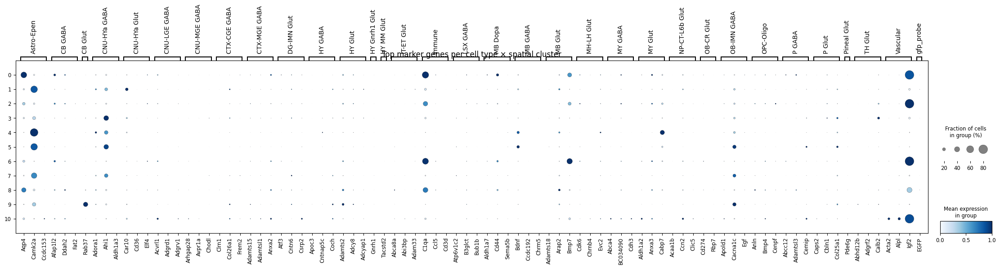

In [27]:
# Pick top 3 marker genes per cell type that are actually in the data
top_genes_per_ct = {}
for ct, genes in marker_allen.items():
    present = [g for g in genes if g in adata.var_names][:3]
    if present:
        top_genes_per_ct[ct] = present

all_top_genes = [g for genes in top_genes_per_ct.values() for g in genes]
# deduplicate while preserving order
seen = set()
plot_genes = [g for g in all_top_genes if not (g in seen or seen.add(g))]

sc.pl.dotplot(
    adata,
    var_names=top_genes_per_ct,   # dict groups genes by cell type in plot
    groupby="leiden",
    use_raw=False,
    cmap="Blues",
    dot_max=0.8,
    standard_scale="var",          # scale each gene 0–1 across clusters
    figsize=(min(len(plot_genes) * 0.45 + 2, 28), 5),
    title="Top marker genes per cell type × spatial cluster",
    save="spatial_celltype_scores_Tuyu_Apr2026 846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_dotplot_8uM.png",
)

# Heatmap of module scores across spatial clusters

/lsf_tmp/290210751.tmpdir/ipykernel_1199659/4255093191.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("leiden")[celltype_scores]


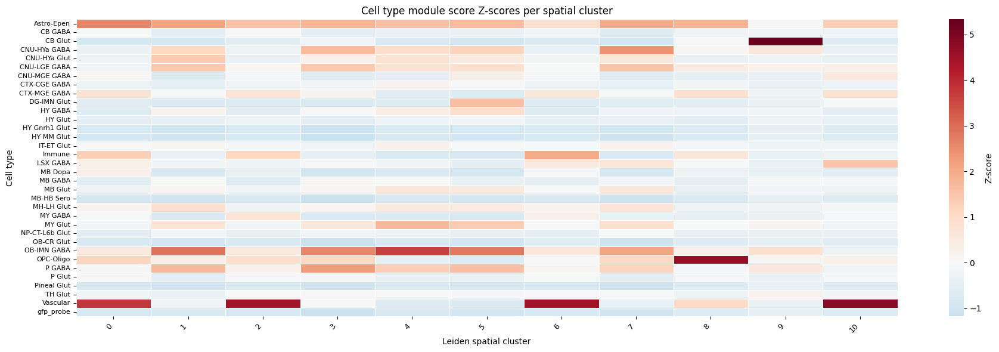

Saved: celltype_score_heatmap.png


In [28]:
score_df = (
    adata.obs[celltype_scores + ["leiden"]]
    .groupby("leiden")[celltype_scores]
    .mean()
)

# Z-score across cell types for each cluster
score_z = score_df.apply(lambda x: (x - x.mean()) / (x.std() + 1e-8), axis=1)

fig, ax = plt.subplots(figsize=(max(len(celltype_scores) * 0.55, 12), 6))
sns.heatmap(
    score_z.T,
    cmap="RdBu_r",
    center=0,
    linewidths=0.4,
    linecolor="white",
    ax=ax,
    cbar_kws={"label": "Z-score"},
    yticklabels=True,
    xticklabels=True,
)
ax.set_xlabel("Leiden spatial cluster")
ax.set_ylabel("Cell type")
ax.set_title("Cell type module score Z-scores per spatial cluster")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.savefig("celltype_score_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: celltype_score_heatmap.png")

In [29]:
adata.write_h5ad("Tuyu_Apr2026/spatial_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_008um.h5ad")

In [30]:
gfp_candidates = ['Gfp', 'GFP', 'EGFP', 'eGFP', 'gfp', 'egfp',
                   'EGFP-L10a', 'Gfp-L10a', 'td-Tomato', 'mCherry']

In [31]:
marker_allen.items()

dict_items([('Astro-Epen', ['2900040C04Rik', 'A330076C08Rik', 'Aqp4', 'C230072F16Rik', 'Camk2a', 'Ccdc153', 'Ccdc170', 'Cnmd', 'Dao', 'Dcc', 'Dnah3', 'Ednrb', 'Emid1', 'Fabp7', 'Fndc3c1', 'Gfap', 'Gja1', 'Gpr37l1', 'Gria2', 'Hepacam', 'Id1', 'Igfbp2', 'Itih3', 'Kcnk10', 'Lhfpl3', 'Myoc', 'Pak1', 'Rarres2', 'Slc7a10', 'Spag17', 'Sspo', 'Thbs4', 'Tmem212', 'Wt1']), ('CB GABA', ['Afap1l2', 'Ddah2', 'Fat2', 'Gabrb1', 'Gldc', 'Il22', 'Ly6d', 'Pcp2', 'Sdk2']), ('CB Glut', ['Rab37']), ('CNU-HYa GABA', ['1700001F09Rik', 'A2ml1', 'Adora1', 'Ahi1', 'Aldh1a3', 'Bcl6', 'Camk2n2', 'Cdh6', 'Cdhr1', 'Col11a1', 'Csmd3', 'Cyp19a1', 'Dock5', 'Ermn', 'Esr2', 'Fosl2', 'Impg1', 'Kcnk13', 'Lamb3', 'Nefl', 'Nup62cl', 'Pcdh10', 'Pcp4', 'Pgm5', 'Pgpep1l', 'Pifo', 'Pmaip1', 'Ptgs1', 'Rab3b', 'Spata13', 'Stac', 'Tacr1', 'Thrsp', 'Tll2', 'Tshz2', 'Upk1b', 'Ust', 'Vdr', 'Vstm2b', 'Zan', 'Zic3']), ('CNU-HYa Glut', ['Car10', 'Cd36', 'Cngb3', 'Elf4', 'Fstl5', 'Gchfr', 'Glipr1', 'Glra3', 'Iigp1', 'Il31ra', 'Krt9', 'La

# Colocalization 

I am testing different colocalization techniques:
- Spot correlationCo-occurrence in same spot
- Bivariate Moran's I (Spatial autocorrelation)
- squidpy nhood enrichment (Neighbor enrichment vs random)
- squidpy co-occurrence (Probability within radius r)

## Spot-Level Co-expression 

In [32]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr

In [33]:
adata

AnnData object with n_obs × n_vars = 78284 × 15028
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_counts', 'Astro-Epen', 'CB GABA', 'CB Glut', 'CNU-HYa GABA', 'CNU-HYa Glut', 'CNU-LGE GABA', 'CNU-MGE GABA', 'CTX-CGE GABA', 'CTX-MGE GABA', 'DG-IMN Glut', 'HY GABA', 'HY Glut', 'HY Gnrh1 Glut', 'HY MM Glut', 'IT-ET Glut', 'Immune', 'LSX GABA', 'MB Dopa', 'MB GABA', 'MB Glut', 'MB-HB Sero', 'MH-LH Glut', 'MY GABA', 'MY Glut', 'NP-CT-L6b Glut', 'OB-CR Glut', 'OB-IMN GABA', 'OPC-Oligo', 'P GABA', 'P Glut', 'Pineal Glut', 'TH Glut', 'Vascular', 'gfp_probe', 'leiden'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions',

In [34]:
score_cols = list(marker_allen.keys())
score_df = adata.obs[score_cols]
#score_df = score_df.drop(columns=["gfp_probe"])

In [35]:
valid_cts = [ct for ct in score_cols 
             if adata.obs[ct].std() > 0 and adata.obs[ct].sum() > 0]

print(f"Kept {len(valid_cts)}/{len(score_cols)} cell types")

Kept 33/34 cell types


In [36]:
# Pearson correlation matrix
corr_matrix = score_df.corr(method='pearson')

In [37]:
corr_matrix

,Astro-Epen,CB GABA,CB Glut,CNU-HYa GABA,CNU-HYa Glut,CNU-LGE GABA,CNU-MGE GABA,CTX-CGE GABA,CTX-MGE GABA,DG-IMN Glut,...,NP-CT-L6b Glut,OB-CR Glut,OB-IMN GABA,OPC-Oligo,P GABA,P Glut,Pineal Glut,TH Glut,Vascular,gfp_probe
Astro-Epen,1.000000,0.112341,-0.073434,-0.173155,-0.033858,-0.112421,0.109667,0.074278,0.293538,0.028588,...,-0.012754,0.032055,-0.124890,0.206486,-0.118219,0.147669,0.007413,0.083878,0.292934,0.024049
CB GABA,0.112341,1.000000,-0.013684,-0.061018,-0.030269,-0.045942,0.066452,0.033261,0.104504,0.010919,...,0.004691,0.007461,-0.049860,0.065732,-0.044125,0.066030,0.000506,0.056371,0.149362,-0.001311
CB Glut,-0.073434,-0.013684,1.000000,0.076551,-0.042949,0.015583,-0.024447,-0.021529,-0.039084,-0.009073,...,-0.029478,-0.004747,0.029153,-0.009998,0.034033,-0.026518,0.008800,0.049967,-0.060624,-0.004789
CNU-HYa GABA,-0.173155,-0.061018,0.076551,1.000000,0.117200,0.153451,-0.126870,-0.033195,-0.187956,-0.000797,...,0.061233,-0.017929,0.173021,-0.084298,0.141122,-0.105108,0.001085,-0.044429,-0.332471,0.002913
CNU-HYa Glut,-0.033858,-0.030269,-0.042949,0.117200,1.000000,0.110791,-0.058835,-0.017062,-0.091098,-0.013780,...,0.040462,0.007420,0.165350,-0.095293,0.097135,-0.062391,-0.001398,-0.050860,-0.178008,0.011604
CNU-LGE GABA,-0.112421,-0.045942,0.015583,0.153451,0.110791,1.000000,-0.081660,-0.026481,-0.099116,-0.006314,...,0.044933,-0.007940,0.126395,-0.040012,0.103657,-0.069255,0.000893,-0.034570,-0.204752,0.005511
CNU-MGE GABA,0.109667,0.066452,-0.024447,-0.126870,-0.058835,-0.081660,1.000000,0.040041,0.148951,0.023430,...,-0.021635,0.016302,-0.061514,0.039266,-0.050400,0.116837,0.008226,0.102960,0.283532,-0.000351
CTX-CGE GABA,0.074278,0.033261,-0.021529,-0.033195,-0.017062,-0.026481,0.040041,1.000000,0.068115,0.016386,...,0.003439,0.009411,-0.016837,0.063846,-0.030327,0.051293,0.006690,0.045950,0.085895,-0.005061
CTX-MGE GABA,0.293538,0.104504,-0.039084,-0.187956,-0.091098,-0.099116,0.148951,0.068115,1.000000,0.011213,...,-0.004189,0.022900,-0.164380,0.188262,-0.123041,0.142829,0.002861,0.106138,0.360789,0.002813
DG-IMN Glut,0.028588,0.010919,-0.009073,-0.000797,-0.013780,-0.006314,0.023430,0.016386,0.011213,1.000000,...,-0.007611,-0.002051,-0.003620,-0.000100,-0.010884,0.022620,-0.000385,0.009358,0.020530,0.005820


In [38]:
corr_matrix.columns[corr_matrix.isna().any(axis=0)]
corr_matrix = corr_matrix.fillna(0)

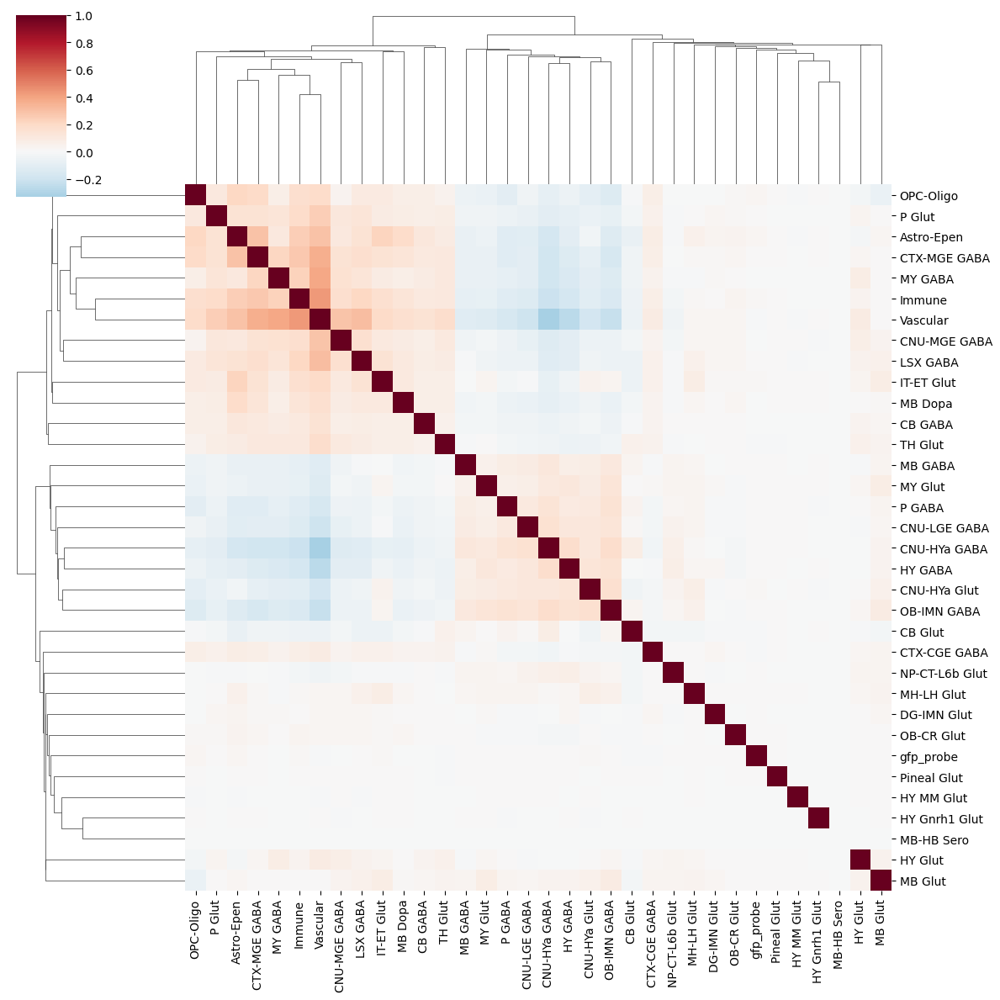

In [39]:
# Plot
import seaborn as sns
sns.clustermap(corr_matrix, cmap='RdBu_r', center=0, figsize=(12,12))

## Spatial Cross-Correlation (Bivariate Moran's I)

Test high expression of cell type A in a spot predicts high expression of cell type B

In [47]:
import numpy as np
import pandas as pd
import libpysal
from esda.moran import Moran_BV
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations

In [48]:
marker_allen.keys()

dict_keys(['Astro-Epen', 'CB GABA', 'CB Glut', 'CNU-HYa GABA', 'CNU-HYa Glut', 'CNU-LGE GABA', 'CNU-MGE GABA', 'CTX-CGE GABA', 'CTX-MGE GABA', 'DG-IMN Glut', 'HY GABA', 'HY Glut', 'HY Gnrh1 Glut', 'HY MM Glut', 'IT-ET Glut', 'Immune', 'LSX GABA', 'MB Dopa', 'MB GABA', 'MB Glut', 'MB-HB Sero', 'MH-LH Glut', 'MY GABA', 'MY Glut', 'NP-CT-L6b Glut', 'OB-CR Glut', 'OB-IMN GABA', 'OPC-Oligo', 'P GABA', 'P Glut', 'Pineal Glut', 'TH Glut', 'Vascular', 'gfp_probe'])

In [78]:
MIN_SCORE = 0.06
MIN_SPOTS = 50
K_NEIGHBORS = 6

In [79]:
masked_scores,passing,w = moran_filter_prep_v1(adata,marker_allen,min_score=MIN_SCORE,min_spots=MIN_SPOTS,k_neighbors=K_NEIGHBORS)
valid_cts = list(passing.keys())

  Astro-Epen                      passing spots: 70285 / 78284
  CB GABA                         passing spots: 10599 / 78284
  CB Glut                         passing spots:  933 / 78284
  CNU-HYa GABA                    passing spots: 55265 / 78284
  CNU-HYa Glut                    passing spots: 37404 / 78284
  CNU-LGE GABA                    passing spots: 54872 / 78284
  CNU-MGE GABA                    passing spots: 15686 / 78284
  CTX-CGE GABA                    passing spots: 20739 / 78284
  CTX-MGE GABA                    passing spots: 40145 / 78284
  DG-IMN Glut                     passing spots: 5129 / 78284
  HY GABA                         passing spots: 28654 / 78284
  HY Glut                         passing spots: 28210 / 78284
  HY Gnrh1 Glut                   SKIPPED — only 48 spots above threshold
  HY MM Glut                      SKIPPED — only 10 spots above threshold
  IT-ET Glut                      passing spots: 43963 / 78284
  Immune                          p

/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/libpysal/weights/distance.py:153: UserWarning: The weights matrix is not fully connected: 
 There are 8 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


### Compute pairwise Bivariate Moran's I

In [70]:
results = []
pairs = list(combinations(valid_cts, 2))
print(f"\nComputing Bivariate Moran's I for {len(pairs)} pairs...")



Computing Bivariate Moran's I for 465 pairs...


In [72]:
n_perms = 5
for ct_a, ct_b in pairs:
    print("testing: ",ct_a," ",ct_b)
    x = masked_scores[ct_a]
    y = masked_scores[ct_b]

    # Skip if either vector is all zeros after masking
    if x.sum() == 0 or y.sum() == 0:
        continue

    bv = Moran_BV(x, y, w, permutations=n_perms)

    results.append({
        'cell_type_A': ct_a,
        'cell_type_B': ct_b,
        'morans_I':    round(bv.I,    4),
        'p_value':     round(bv.p_sim, 4),
        'z_score':     round(bv.z_sim, 3),
        'significant': bv.p_sim < 0.05,
        'n_spots_A':   passing[ct_a].sum(),
        'n_spots_B':   passing[ct_b].sum(),
    })

testing:  Astro-Epen   CB GABA
testing:  Astro-Epen   CB Glut
testing:  Astro-Epen   CNU-HYa GABA
testing:  Astro-Epen   CNU-HYa Glut
testing:  Astro-Epen   CNU-LGE GABA
testing:  Astro-Epen   CNU-MGE GABA
testing:  Astro-Epen   CTX-CGE GABA
testing:  Astro-Epen   CTX-MGE GABA
testing:  Astro-Epen   DG-IMN Glut
testing:  Astro-Epen   HY GABA
testing:  Astro-Epen   HY Glut
testing:  Astro-Epen   IT-ET Glut
testing:  Astro-Epen   Immune
testing:  Astro-Epen   LSX GABA
testing:  Astro-Epen   MB Dopa
testing:  Astro-Epen   MB GABA
testing:  Astro-Epen   MB Glut
testing:  Astro-Epen   MH-LH Glut
testing:  Astro-Epen   MY GABA
testing:  Astro-Epen   MY Glut
testing:  Astro-Epen   NP-CT-L6b Glut
testing:  Astro-Epen   OB-CR Glut
testing:  Astro-Epen   OB-IMN GABA
testing:  Astro-Epen   OPC-Oligo
testing:  Astro-Epen   P GABA
testing:  Astro-Epen   P Glut
testing:  Astro-Epen   Pineal Glut
testing:  Astro-Epen   TH Glut
testing:  Astro-Epen   Vascular
testing:  Astro-Epen   gfp_probe
testing: 

In [73]:
results_df = pd.DataFrame(results).sort_values('morans_I', ascending=False)
print(results_df.head(20).to_string(index=False))
#results_df.to_csv("bivariate_morans_I_results.csv", index=False)

# ── Step 5: Pivot to matrix for heatmap ──────────────────────────────────────
# Fill symmetric matrix
I_matrix  = pd.DataFrame(np.nan,  index=valid_cts, columns=valid_cts)
p_matrix  = pd.DataFrame(np.nan,  index=valid_cts, columns=valid_cts)

for _, row in results_df.iterrows():
    a, b = row['cell_type_A'], row['cell_type_B']
    I_matrix.loc[a, b] = row['morans_I']
    I_matrix.loc[b, a] = row['morans_I']   # symmetric
    p_matrix.loc[a, b] = row['p_value']
    p_matrix.loc[b, a] = row['p_value']

np.fill_diagonal(I_matrix.values, 1.0)   # self-correlation = 1
np.fill_diagonal(p_matrix.values, 0.0)

 cell_type_A  cell_type_B  morans_I  p_value  z_score  significant  n_spots_A  n_spots_B
      Immune     Vascular    0.4224   0.1667  186.749        False      28194      38631
     MY GABA     Vascular    0.3689   0.1667  146.627        False      20683      38631
CTX-MGE GABA     Vascular    0.3488   0.1667  207.288        False      40145      38631
  Astro-Epen     Vascular    0.3003   0.0010  114.533         True      70285      38631
  Astro-Epen     Vascular    0.3003   0.1667  109.816        False      70285      38631
    LSX GABA     Vascular    0.2972   0.1667  211.828        False      39772      38631
CNU-MGE GABA     Vascular    0.2718   0.1667  118.377        False      15686      38631
  Astro-Epen CTX-MGE GABA    0.2686   0.0010  103.665         True      70285      40145
  Astro-Epen CTX-MGE GABA    0.2686   0.1667  133.700        False      70285      40145
CTX-MGE GABA       Immune    0.2622   0.1667  254.820        False      40145      28194
  Astro-Epen       Im

In [76]:
results_df[results_df['cell_type_B']=='gfp_probe']

,cell_type_A,cell_type_B,morans_I,p_value,z_score,significant,n_spots_A,n_spots_B
29,Astro-Epen,gfp_probe,0.0186,0.0010,6.966,True,70285,151
156,Astro-Epen,gfp_probe,0.0186,0.1667,7.684,False,70285,151
455,Immune,gfp_probe,0.0137,0.1667,6.496,False,28194,151
438,IT-ET Glut,gfp_probe,0.0103,0.1667,20.255,False,43963,151
266,CNU-HYa Glut,gfp_probe,0.0100,0.1667,6.358,False,37404,151
576,OPC-Oligo,gfp_probe,0.0092,0.1667,3.998,False,28241,151
581,P GABA,gfp_probe,0.0073,0.1667,6.592,False,52373,151
240,CNU-HYa GABA,gfp_probe,0.0067,0.1667,7.790,False,55265,151
113,CNU-HYa GABA,gfp_probe,0.0067,0.0030,2.841,True,55265,151
291,CNU-LGE GABA,gfp_probe,0.0064,0.1667,5.250,False,54872,151


### Plot heatmap with significance mask

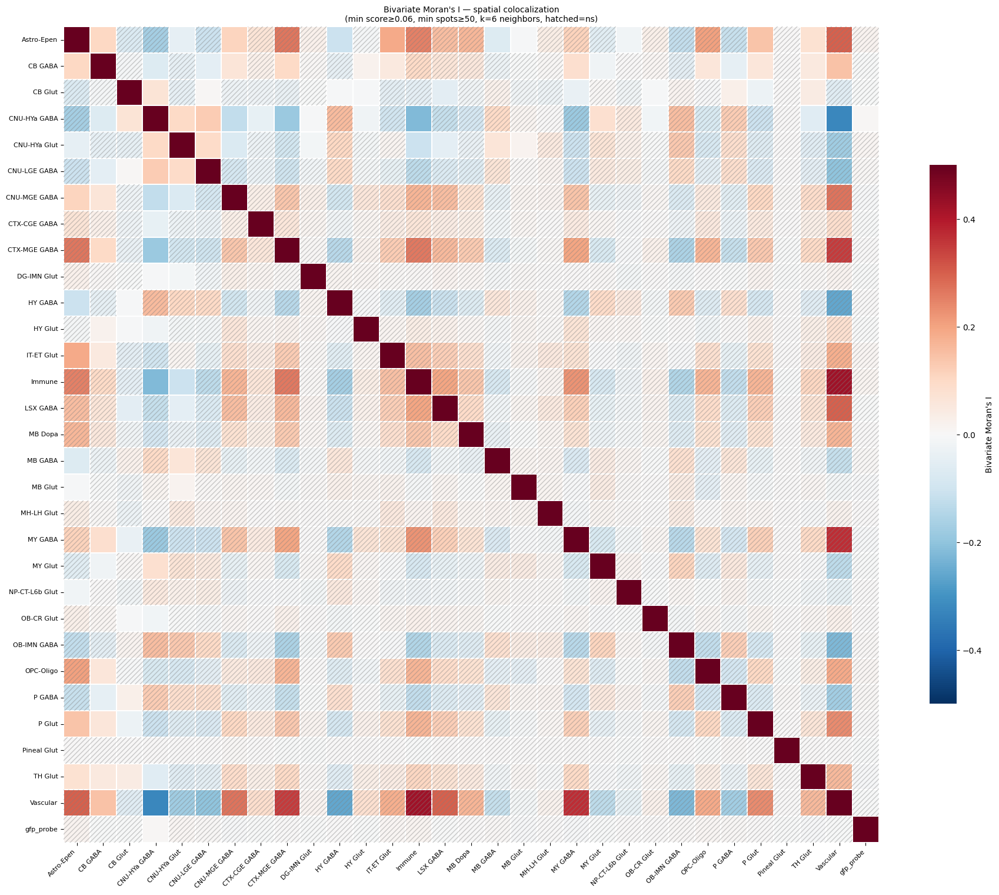

In [81]:
sig_mask   = (p_matrix >= 0.05) | I_matrix.isna()   # mask non-significant
annot_mask = I_matrix.copy()
annot_mask[sig_mask] = np.nan

fig, ax = plt.subplots(figsize=(max(len(valid_cts)*0.6, 10),
                                max(len(valid_cts)*0.6, 10)))

sns.heatmap(
    I_matrix.fillna(0),
    ax       = ax,
    cmap     = 'RdBu_r',
    center   = 0,
    vmin     = -0.5,
    vmax     = 0.5,
    linewidths = 0.3,
    linecolor  = 'white',
    square   = True,
    cbar_kws = {'label': "Bivariate Moran's I", 'shrink': 0.5},
    xticklabels = True,
    yticklabels = True,
)

# Hatch non-significant cells
for i in range(len(valid_cts)):
    for j in range(len(valid_cts)):
        if sig_mask.iloc[i, j]:
            ax.add_patch(plt.Rectangle(
                (j, i), 1, 1,
                fill=False, hatch='////', edgecolor='gray',
                linewidth=0, alpha=0.4
            ))

ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0,  fontsize=8)
ax.set_title(
    f"Bivariate Moran's I — spatial colocalization\n"
    f"(min score≥{MIN_SCORE}, min spots≥{MIN_SPOTS}, "
    f"k={K_NEIGHBORS} neighbors, hatched=ns)",
    fontsize=10
)

plt.tight_layout()
#fig.savefig("bivariate_morans_I_heatmap.png", dpi=200, bbox_inches="tight")
#plt.close(fig)


### Retesting with just gfp_probe

In [82]:
n_perms = 100
results_gfp = []
for ct_a, ct_b in pairs:
    if ct_a != 'gfp_probe' and ct_b != 'gfp_probe':
        continue
        
    print("testing: ",ct_a," ",ct_b)
    x = masked_scores[ct_a]
    y = masked_scores[ct_b]

    # Skip if either vector is all zeros after masking
    if x.sum() == 0 or y.sum() == 0:
        continue

    bv = Moran_BV(x, y, w, permutations=n_perms)

    results_gfp.append({
        'cell_type_A': ct_a,
        'cell_type_B': ct_b,
        'morans_I':    round(bv.I,    4),
        'p_value':     round(bv.p_sim, 4),
        'z_score':     round(bv.z_sim, 3),
        'significant': bv.p_sim < 0.05,
        'n_spots_A':   passing[ct_a].sum(),
        'n_spots_B':   passing[ct_b].sum(),
    })

testing:  Astro-Epen   gfp_probe
testing:  CB GABA   gfp_probe
testing:  CB Glut   gfp_probe
testing:  CNU-HYa GABA   gfp_probe
testing:  CNU-HYa Glut   gfp_probe
testing:  CNU-LGE GABA   gfp_probe
testing:  CNU-MGE GABA   gfp_probe
testing:  CTX-CGE GABA   gfp_probe
testing:  CTX-MGE GABA   gfp_probe
testing:  DG-IMN Glut   gfp_probe
testing:  HY GABA   gfp_probe
testing:  HY Glut   gfp_probe
testing:  IT-ET Glut   gfp_probe
testing:  Immune   gfp_probe
testing:  LSX GABA   gfp_probe
testing:  MB Dopa   gfp_probe
testing:  MB GABA   gfp_probe
testing:  MB Glut   gfp_probe
testing:  MH-LH Glut   gfp_probe
testing:  MY GABA   gfp_probe
testing:  MY Glut   gfp_probe
testing:  NP-CT-L6b Glut   gfp_probe
testing:  OB-CR Glut   gfp_probe
testing:  OB-IMN GABA   gfp_probe
testing:  OPC-Oligo   gfp_probe
testing:  P GABA   gfp_probe
testing:  P Glut   gfp_probe
testing:  Pineal Glut   gfp_probe
testing:  TH Glut   gfp_probe
testing:  Vascular   gfp_probe


In [84]:
results_gfp = pd.DataFrame(results_gfp).sort_values('morans_I', ascending=False)
results_gfp

,cell_type_A,cell_type_B,morans_I,p_value,z_score,significant,n_spots_A,n_spots_B
0,Astro-Epen,gfp_probe,0.0186,0.0099,7.834,True,70285,151
13,Immune,gfp_probe,0.0137,0.0099,5.293,True,28194,151
12,IT-ET Glut,gfp_probe,0.0103,0.0099,5.431,True,43963,151
4,CNU-HYa Glut,gfp_probe,0.0100,0.0099,5.743,True,37404,151
24,OPC-Oligo,gfp_probe,0.0092,0.0099,4.258,True,28241,151
25,P GABA,gfp_probe,0.0073,0.0099,3.878,True,52373,151
3,CNU-HYa GABA,gfp_probe,0.0067,0.0099,3.153,True,55265,151
5,CNU-LGE GABA,gfp_probe,0.0064,0.0099,3.618,True,54872,151
23,OB-IMN GABA,gfp_probe,0.0061,0.0099,3.135,True,64664,151
16,MB GABA,gfp_probe,0.0054,0.0099,3.280,True,25432,151


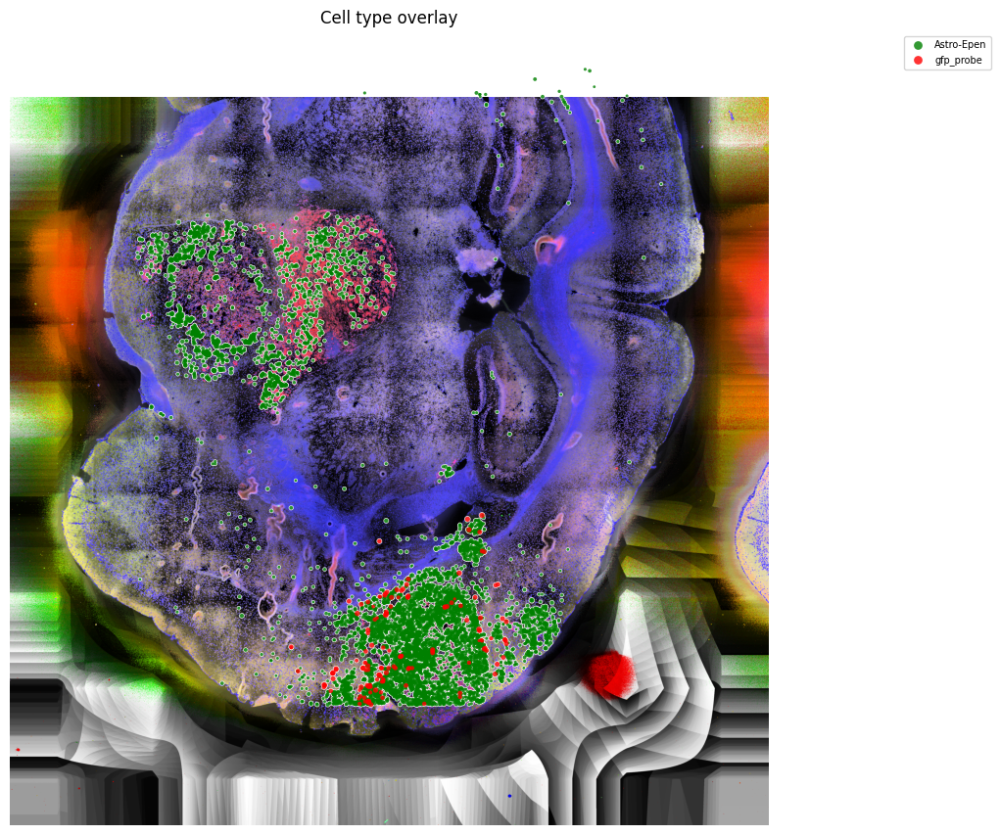

In [96]:
#plot top 
#celltypes_to_overlay = [
#    "Astro-Epen","Immune","IT-ET Glut","CNU-HYa Glut","OPC-Oligo","P GABA","gfp_probe"
#]

celltypes_to_overlay = ["Astro-Epen","gfp_probe"]

fig = plot_celltype_overlay(
    adata,
    celltypes=celltypes_to_overlay,
    img_key="hires",
    spot_size=4,          # increase if spots are hard to see originally 8
    alpha=0.8,            # originally 0.8
    min_threshold=0.90,    # only show top 50% expressing spots per cell type
    colors = ['green','red']
)
#fig.savefig("celltype_overlay_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_8uM_moranI_top.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

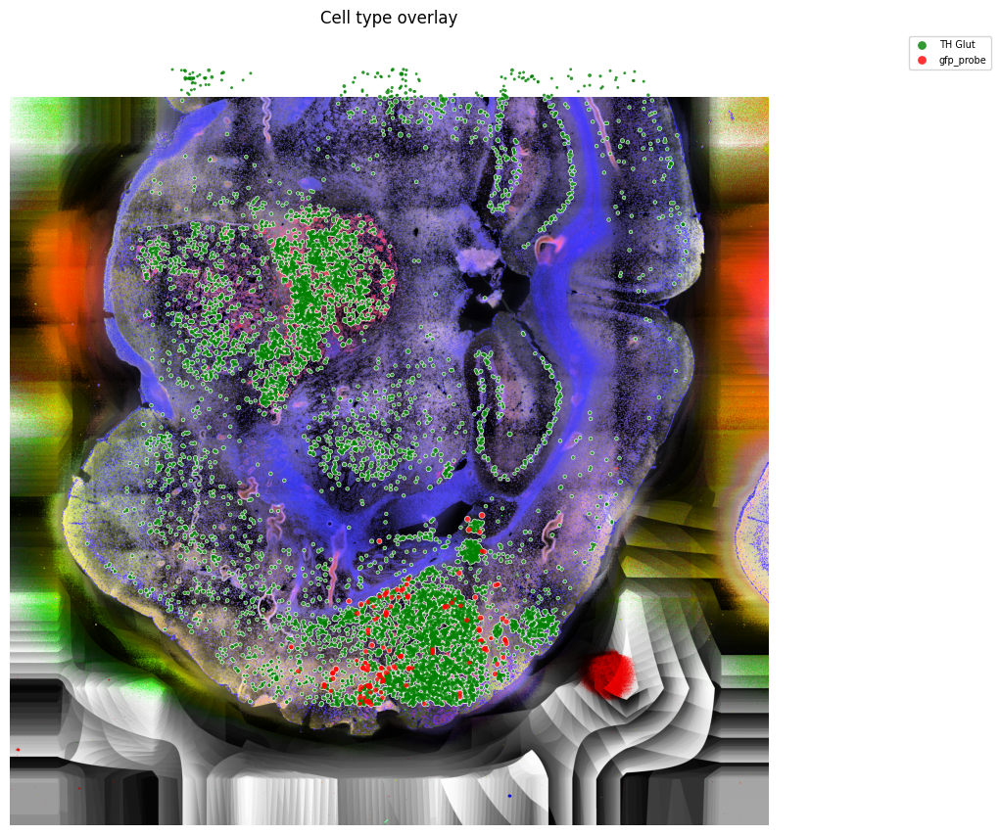

In [97]:
#plot bottom
#celltypes_to_overlay = [
#    "CB Glut","MB Glut","CNU-MGE GABA","MY GABA","TH Glut","Vascular","gfp_probe"
#]

celltypes_to_overlay = ["TH Glut","gfp_probe"]

fig = plot_celltype_overlay(
    adata,
    celltypes=celltypes_to_overlay,
    img_key="hires",
    spot_size=4,          # increase if spots are hard to see originally 8
    alpha=0.8,            # originally 0.8
    min_threshold=0.90,    # only show top 50% expressing spots per cell type
    colors = ['green','red']
)
#fig.savefig("celltype_overlay_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_8uM_moranI_bot.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

In [ ]:
adata